# Time against emissions: the commutes of New York and Houston

What a lower-carbon commute costs in minutes, and where. The input is the commute table of
05.10 (run `us-v4-agency`): every tract-to-tract commuting flow of LODES with its workers and,
per mode, the door-to-door minutes, the kilometres and the one-way grams CO₂e at the US factors
of `factors/us-v4/`. Modes are transit, petrol car, bicycle and e-bike, with the BEV car as a
scenario on the car's trips; walking is not a mode of its own here and enters only as the
access and egress legs of transit. Weekly figures follow the carbon-budgets paper: four return
commutes a week, against the paper's budgets of 7 kg CO₂e per week (2030) and 3 kg (2050).

| Step | What we do |
|---|---|
| 1. Inputs | The commute tables, one wide row per flow, and the kept tracts |
| 2. Time against emissions by mode | Where each mode's commutes sit in the minutes-by-grams plane, worker-weighted, and the mode medians |
| 3. Who can leave the car | For every commuter who can drive: whether transit, the e-bike or the bicycle is available at all, and how that share grows as the driver accepts more extra minutes |
| 4. The time-budget frontier | The cleanest mode within a commute-time allowance, and the share of commuters whose weekly commute then fits the budgets, as the allowance grows |
| 5. Maps | By home tract, New York beside Houston: the time penalty of transit against the car, the share of residents with a cleaner mode within a small time cost, and compliance with the 2030 budget at a 60-minute allowance |

Everything is worker-weighted: a flow counts as many commuters as it carries. A mode is
available to a commuter when it has an itinerary under the routing caps of 05.9 (120 minutes on
the street, 30-minute access and egress on transit) **and**, for the bicycle and the e-bike,
when the ride takes at most 45 minutes one way: longer rides are not a daily commute for most
people and are set aside as unavailable (`MODE_CAPS_MIN` in the parameters). A commuter without
the mode is excluded from that mode's statistics and counted as such.

In [1]:
from pathlib import Path

import contextily as ctx
import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

YEAR = 2023
RUN_TAG = "us-v4-agency"
RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

AREAS = {"New York": RESULTS / "new-york", "Houston": RESULTS / "houston"}
MODES = ["transit", "car", "car_bev", "bicycle", "e_bike"]   # walking counts only as the access and egress legs of transit
CHOICE_MODES = ["transit", "car", "bicycle", "e_bike"]            # the modes a commuter can choose between today
CHOICE_MODES_BEV = ["transit", "car_bev", "bicycle", "e_bike"]    # the same choice set with an electrified car fleet
COMMUTES_PER_WEEK = 4
WEEKLY_PER_GRAM = 2 * COMMUTES_PER_WEEK / 1000      # one-way grams -> weekly kg
BUDGETS_KG = {"2030 budget, 7 kg/week": 7.0, "2050 budget, 3 kg/week": 3.0}
MODE_CAPS_MIN = {"bicycle": 45, "e_bike": 45}   # a ride longer than this, one way, does not count as an available commute
TOLERANCE_MIN = 15      # map 2: a cleaner mode counts as "within reach" when at most this much slower than the car
ALLOWANCE_MAP = 60      # map 3: the one-way commute-time allowance drawn; the frontier of step 4 sweeps 15 to 120

# Okabe-Ito hues, one per mode, in the fixed order of 05.9 and 05.10; grey for "none".
COLOURS = {"transit": "#0072B2", "car": "#D55E00", "car_bev": "#E69F00", "bicycle": "#009E73", "e_bike": "#56B4E9", "walk": "#999999"}
LABELS = {"transit": "transit", "car": "car (petrol)", "car_bev": "car (BEV scenario)", "bicycle": "bicycle", "e_bike": "e-bike", "walk": "walk"}
SEQUENTIAL = "Blues"
DIVERGING = mcolors.LinearSegmentedColormap.from_list("transit_vs_car", ["#0072B2", "#e6e6e6", "#D55E00"])   # blue: transit faster; orange: slower
NO_DATA = "#d9d9d9"

plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 9,
                     "axes.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "svg.fonttype": "none", "pdf.fonttype": 42})
BASEMAP = ctx.providers.Esri.WorldGrayCanvas
ctx.set_cache_dir(str(Path.home() / ".cache" / "contextily"))

## 1. Inputs

The long commute table of each area pivoted wide, one row per flow with `minutes_<mode>`,
`km_<mode>` and `grams_<mode>`, plus the kept tract polygons for the maps.

In [2]:
def weighted_median(values, weights):
    values, weights = np.asarray(values, dtype=float), np.asarray(weights, dtype=float)
    keep = ~np.isnan(values)
    values, weights = values[keep], weights[keep]
    if len(values) == 0 or weights.sum() == 0:
        return np.nan
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][np.searchsorted(cumulative, 0.5)]


def weighted_quantiles(values, weights, quantiles):
    values, weights = np.asarray(values, dtype=float), np.asarray(weights, dtype=float)
    keep = ~np.isnan(values)
    values, weights = values[keep], weights[keep]
    if len(values) == 0 or weights.sum() == 0:
        return [np.nan] * len(quantiles)
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return [values[order][np.searchsorted(cumulative, q)] for q in quantiles]


def load_wide(folder):
    long = pd.read_parquet(folder / f"commute-emissions-{RUN_TAG}-{YEAR}.parquet", columns=["from_id", "to_id", "workers", "mode", "minutes", "km", "grams"])
    wide = long.pivot(index=["from_id", "to_id", "workers"], columns="mode", values=["minutes", "km", "grams"])
    wide.columns = [f"{value}_{mode}" for value, mode in wide.columns]
    wide = wide.reset_index()
    for mode, cap in MODE_CAPS_MIN.items():
        over = wide[f"minutes_{mode}"] > cap
        wide.loc[over, [f"minutes_{mode}", f"km_{mode}", f"grams_{mode}"]] = np.nan
    return wide


flows, tracts = {}, {}
for area, folder in AREAS.items():
    flows[area] = load_wide(folder)
    polygons = gpd.read_parquet(folder / f"tracts-kept-{YEAR}.parquet")[["tract", "geometry"]].to_crs("EPSG:3857")
    polygons["tract"] = polygons["tract"].astype(str)
    tracts[area] = polygons
    reach = {mode: flows[area].loc[flows[area][f"minutes_{mode}"].notna(), "workers"].sum() / flows[area]["workers"].sum() for mode in MODES}
    print(f"{area}: {len(flows[area]):,} flows, {flows[area]['workers'].sum():,} commuters, {len(polygons):,} tracts; share with the mode available: "
          + ", ".join(f"{LABELS[m]} {s:.2f}" for m, s in reach.items()))
print(f"bicycle and e-bike rides over {MODE_CAPS_MIN['bicycle']} min one way are set aside as unavailable")

New York: 2,408,018 flows, 6,708,469 commuters, 4,589 tracts; share with the mode available: transit 0.90, car (petrol) 0.99, car (BEV scenario) 0.99, bicycle 0.40, e-bike 0.45


Houston: 608,199 flows, 2,114,670 commuters, 1,447 tracts; share with the mode available: transit 0.31, car (petrol) 1.00, car (BEV scenario) 1.00, bicycle 0.24, e-bike 0.27
bicycle and e-bike rides over 45 min one way are set aside as unavailable


## 2. Time against emissions by mode

Each panel is the worker-weighted density of one-way commutes in the plane of door-to-door
minutes and kilograms CO₂e, one mode per row, the two areas side by side on shared axes. The
dot and bars in each panel mark the mode's worker-weighted median and interquartile range. The
car and its BEV scenario share one panel: same minutes, lower grams.

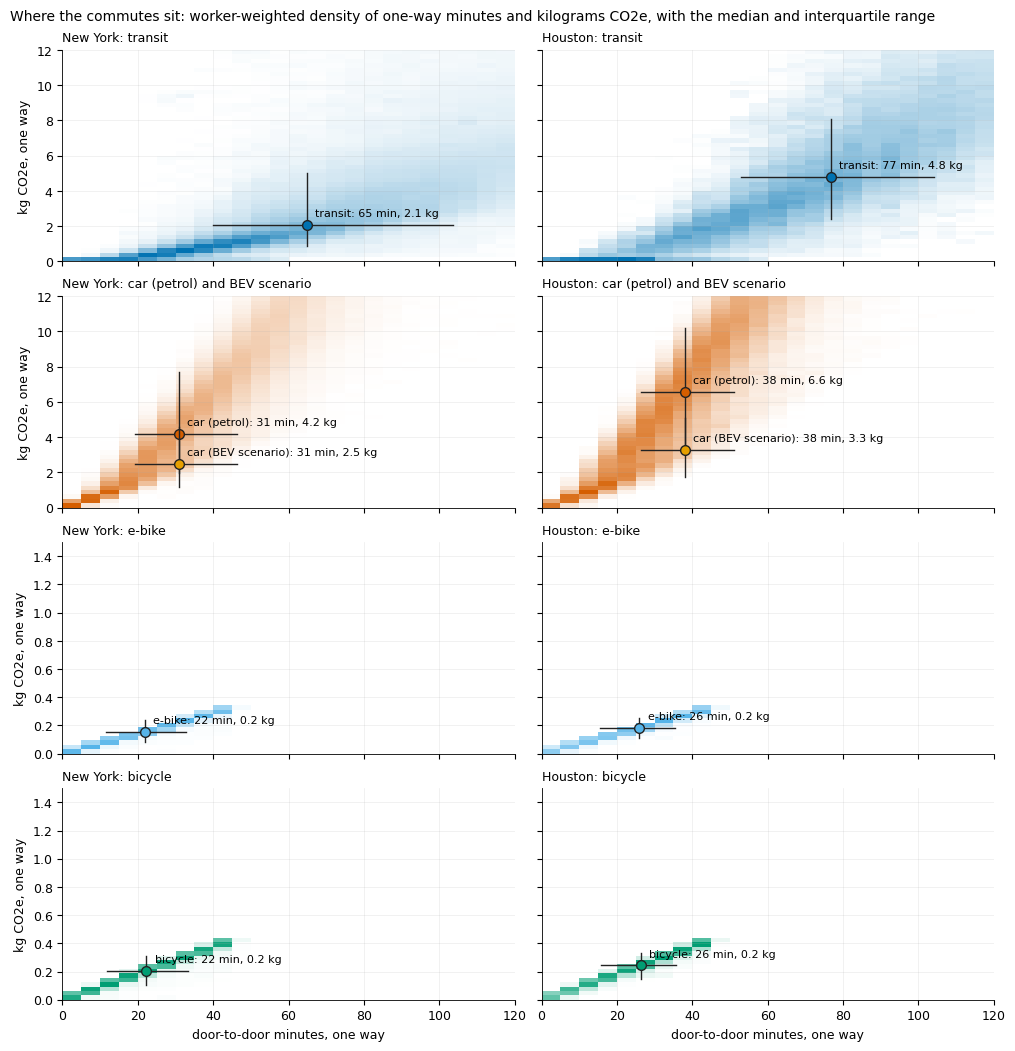

commuters with an itinerary  minutes p25  minutes median  \
area     mode                                                                
New York transit                      6067861         39.9            64.8   
Houston  transit                       664895         52.8            76.8   
New York car                          6630009         19.3            30.9   
         car_bev                      6630009         19.3            30.9   
Houston  car                          2106212         26.4            38.0   
         car_bev                      2106212         26.4            38.0   
New York e_bike                       2992415         11.5            21.9   
Houston  e_bike                        581420         15.5            25.9   
New York bicycle                      2675542         11.7            22.3   
Houston  bicycle                       499843         15.7            26.3   

                  minutes p75  kg p25  kg median  kg p75  
area     mode                                             
New York transit        103.5     0.9        2.1     5.0  
Houston  transit        104.0     2.4        4.8     8.1  
New York car             46.3     1.9        4.2     7.7  
         car_bev         46.3     1.2        2.5     4.6  
Houston  car             51.2     3.5        6.6    10.2  
         car_bev         51.2     1.7        3.3     5.1  
New York e_bike          32.9     0.1        0.2     0.2  
Houston  e_bike          35.5     0.1        0.2     0.3  
New York bicycle         33.4     0.1        0.2     0.3  
Houston  bicycle         35.7     0.1        0.2     0.3

In [3]:
MINUTE_BINS = np.arange(0, 125, 5)
PANELS = [("transit", ["transit"], 12), ("car", ["car", "car_bev"], 12), ("e_bike", ["e_bike"], 1.5), ("bicycle", ["bicycle"], 1.5)]   # mode(s) per row and the row's kg axis

figure, axes = plt.subplots(nrows=len(PANELS), ncols=len(AREAS), figsize=(5 * len(AREAS), 2.6 * len(PANELS)), sharex=True, sharey="row", layout="constrained")
mode_summary = []
for row, (panel_mode, modes, kg_top) in enumerate(PANELS):
    for column, (area, table) in enumerate(flows.items()):
        axis = axes[row, column]
        base = table.loc[table[f"minutes_{panel_mode}"].notna()]
        kg_bins = np.linspace(0, kg_top, 49)
        density, _, _ = np.histogram2d(base[f"minutes_{panel_mode}"], base[f"grams_{panel_mode}"] / 1000, bins=[MINUTE_BINS, kg_bins], weights=base["workers"])
        density = density / base["workers"].sum() * 100
        cmap = mcolors.LinearSegmentedColormap.from_list(panel_mode, ["#ffffff", COLOURS[panel_mode]])
        axis.pcolormesh(MINUTE_BINS, kg_bins, density.T, cmap=cmap, norm=mcolors.PowerNorm(0.5, vmin=0, vmax=max(density.max(), 1e-9)), rasterized=True)
        for mode in modes:
            rows = table.loc[table[f"minutes_{mode}"].notna()]
            t25, t50, t75 = weighted_quantiles(rows[f"minutes_{mode}"], rows["workers"], [0.25, 0.5, 0.75])
            g25, g50, g75 = weighted_quantiles(rows[f"grams_{mode}"] / 1000, rows["workers"], [0.25, 0.5, 0.75])
            axis.plot([t25, t75], [g50, g50], color="#222222", linewidth=1)
            axis.plot([t50, t50], [g25, g75], color="#222222", linewidth=1)
            axis.plot(t50, g50, "o", markerfacecolor=COLOURS[mode], markeredgecolor="#222222", markersize=7)
            axis.annotate(f"{LABELS[mode]}: {t50:.0f} min, {g50:.1f} kg", (t50, g50), xytext=(6, 6), textcoords="offset points", fontsize=8)
            mode_summary.append({"area": area, "mode": mode, "commuters with an itinerary": int(rows["workers"].sum()),
                                 "minutes p25": t25, "minutes median": t50, "minutes p75": t75, "kg p25": g25, "kg median": g50, "kg p75": g75})
        axis.set_title(f"{area}: {LABELS[panel_mode]}" + (" and BEV scenario" if len(modes) > 1 else ""), loc="left", fontsize=9)
        axis.set_ylim(0, kg_top)
        axis.grid(alpha=0.25, linewidth=0.5)
        if row == len(PANELS) - 1:
            axis.set_xlabel("door-to-door minutes, one way")
        if column == 0:
            axis.set_ylabel("kg CO2e, one way")
axes[0, 0].set_xlim(0, 120)
figure.suptitle("Where the commutes sit: worker-weighted density of one-way minutes and kilograms CO2e, with the median and interquartile range", x=0, ha="left", fontsize=10)
figure.savefig(FIGURES / f"05.11-time-vs-emissions-density-{RUN_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

mode_summary = pd.DataFrame(mode_summary).set_index(["area", "mode"])
mode_summary.round(1)

## 3. Who can leave the car, and at what time cost

For every commuter who can drive, whether transit, the e-bike or the bicycle exists as an
alternative at all, and how many drivers would have it if they accepted a given number of
extra minutes against their drive.
The curves read like accessibility curves: at zero extra minutes, the share of drivers for
whom the alternative is as fast as the car; moving right, the share who have it within 10,
20, 30 or more extra minutes; the flat end is the share who have the alternative at all. The
gap between the flat end and 100% is the share of drivers for whom the alternative does not
exist under the caps: no transit itinerary with a 30-minute walk at each end, or a ride
longer than 45 minutes. The table beside it gives the availability, the median extra minutes
among those who have the alternative, and the weekly kilograms it saves them.

alternatives to the petrol car among commuters with a car itinerary; shares are of all drivers unless stated:


available to  as fast as the car  within 15 extra min  \
area     alternative                                                          
New York transit             0.908               0.005                0.181   
         e-bike              0.451               0.141                0.420   
         bicycle             0.403               0.060                0.361   
Houston  transit             0.315               0.000                0.022   
         e-bike              0.276               0.066                0.247   
         bicycle             0.237               0.029                0.205   

                      within 30 extra min  \
area     alternative                        
New York transit                    0.426   
         e-bike                     0.451   
         bicycle                    0.403   
Houston  transit                    0.076   
         e-bike                     0.276   
         bicycle                    0.237   

                      median extra minutes, where available  \
area     alternative                                          
New York transit                                       32.2   
         e-bike                                         2.0   
         bicycle                                        3.8   
Houston  transit                                       48.3   
         e-bike                                         3.6   
         bicycle                                        5.4   

                      median kg saved per week, where available  \
area     alternative                                              
New York transit                                           10.9   
         e-bike                                            12.9   
         bicycle                                           10.8   
Houston  transit                                           -4.5   
         e-bike                                            15.1   
         bicycle                                           12.6   

                      share of those who save nothing or emit more  
area     alternative                                                
New York transit                                             0.150  
         e-bike                                              0.001  
         bicycle                                             0.001  
Houston  transit                                             0.689  
         e-bike                                              0.000  
         bicycle                                             0.001

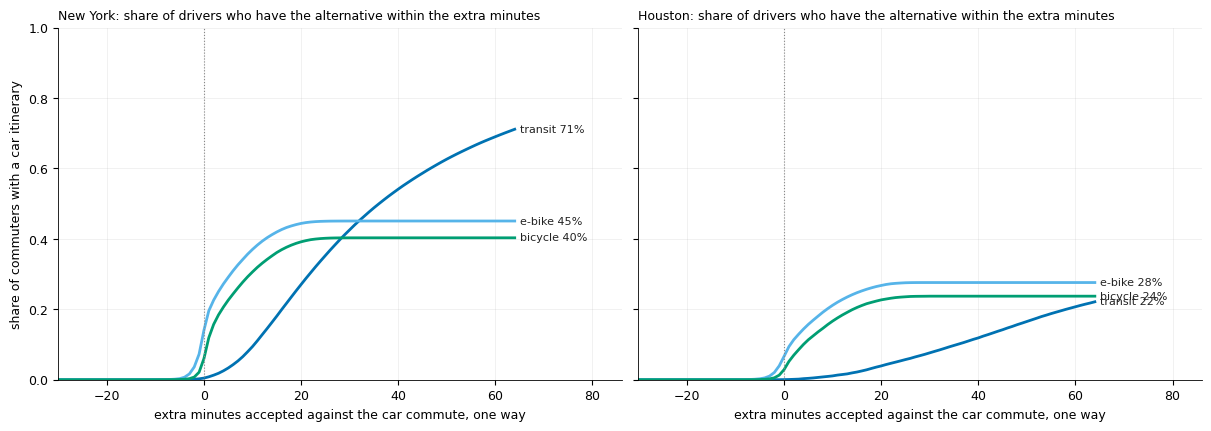

In [4]:
ALTERNATIVES = ["transit", "e_bike", "bicycle"]
EXTRA_MINUTES = np.arange(-30, 65, 1)

access_rows, curves = [], {}
for area, table in flows.items():
    drivers = table.loc[table["minutes_car"].notna()]
    total = drivers["workers"].sum()
    for mode in ALTERNATIVES:
        both = drivers.loc[drivers[f"minutes_{mode}"].notna()]
        extra = (both[f"minutes_{mode}"] - both["minutes_car"]).to_numpy()
        weights = both["workers"].to_numpy()
        saved = (both["grams_car"] - both[f"grams_{mode}"]).to_numpy() * WEEKLY_PER_GRAM
        order = np.argsort(extra)
        cumulative = np.cumsum(weights[order]) / total
        curves[(area, mode)] = np.interp(EXTRA_MINUTES, extra[order], cumulative, left=0.0)
        access_rows.append({"area": area, "alternative": LABELS[mode], "available to": weights.sum() / total,
                            "as fast as the car": weights[extra <= 0].sum() / total,
                            "within 15 extra min": weights[extra <= 15].sum() / total,
                            "within 30 extra min": weights[extra <= 30].sum() / total,
                            "median extra minutes, where available": weighted_median(extra, weights),
                            "median kg saved per week, where available": weighted_median(saved, weights),
                            "share of those who save nothing or emit more": weights[saved <= 0].sum() / max(weights.sum(), 1)})

access = pd.DataFrame(access_rows).set_index(["area", "alternative"])
print("alternatives to the petrol car among commuters with a car itinerary; shares are of all drivers unless stated:")
display(access.round({"available to": 3, "as fast as the car": 3, "within 15 extra min": 3, "within 30 extra min": 3,
                      "median extra minutes, where available": 1, "median kg saved per week, where available": 1, "share of those who save nothing or emit more": 3}))

figure, axes = plt.subplots(ncols=len(AREAS), figsize=(6 * len(AREAS), 4.2), sharey=True, layout="constrained")
for axis, area in zip(axes, AREAS):
    for mode in ALTERNATIVES:
        curve = curves[(area, mode)]
        axis.plot(EXTRA_MINUTES, curve, color=COLOURS[mode], linewidth=2)
        axis.annotate(f"{LABELS[mode]} {curve[-1]:.0%}", (EXTRA_MINUTES[-1], curve[-1]), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color="#222222")
    axis.axvline(0, color="#888888", linewidth=0.8, linestyle=":")
    axis.set_xlim(EXTRA_MINUTES[0], EXTRA_MINUTES[-1] + 22)
    axis.set_ylim(0, 1)
    axis.set_xlabel("extra minutes accepted against the car commute, one way")
    axis.set_title(f"{area}: share of drivers who have the alternative within the extra minutes", loc="left", fontsize=9)
    axis.grid(alpha=0.25, linewidth=0.5)
axes[0].set_ylabel("share of commuters with a car itinerary")
figure.savefig(FIGURES / f"05.11-alternatives-to-the-car-{RUN_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. The time-budget frontier

Give every commuter a commute-time allowance and let them take the cleanest mode that gets
them to work within it (the bicycle and the e-bike only up to their 45-minute cap); a commuter
with no mode inside the allowance takes the fastest mode available. As the allowance grows, cleaner but slower modes become admissible and emissions
fall. The curves show the share of commuters whose weekly commute then fits the 2030 and 2050
budgets, for today's choice set (petrol car) and for the BEV scenario, with the car-only and
cleanest-ever references. The second panel shows which mode the cleanest choice is, by
allowance.

New York, 2030 budget, 7 kg/week: car only 0.116 of commuters under budget; cleanest mode regardless of time 0.454
New York, 2050 budget, 3 kg/week: car only 0.047 of commuters under budget; cleanest mode regardless of time 0.449


Houston, 2030 budget, 7 kg/week: car only 0.049 of commuters under budget; cleanest mode regardless of time 0.276
Houston, 2050 budget, 3 kg/week: car only 0.017 of commuters under budget; cleanest mode regardless of time 0.276


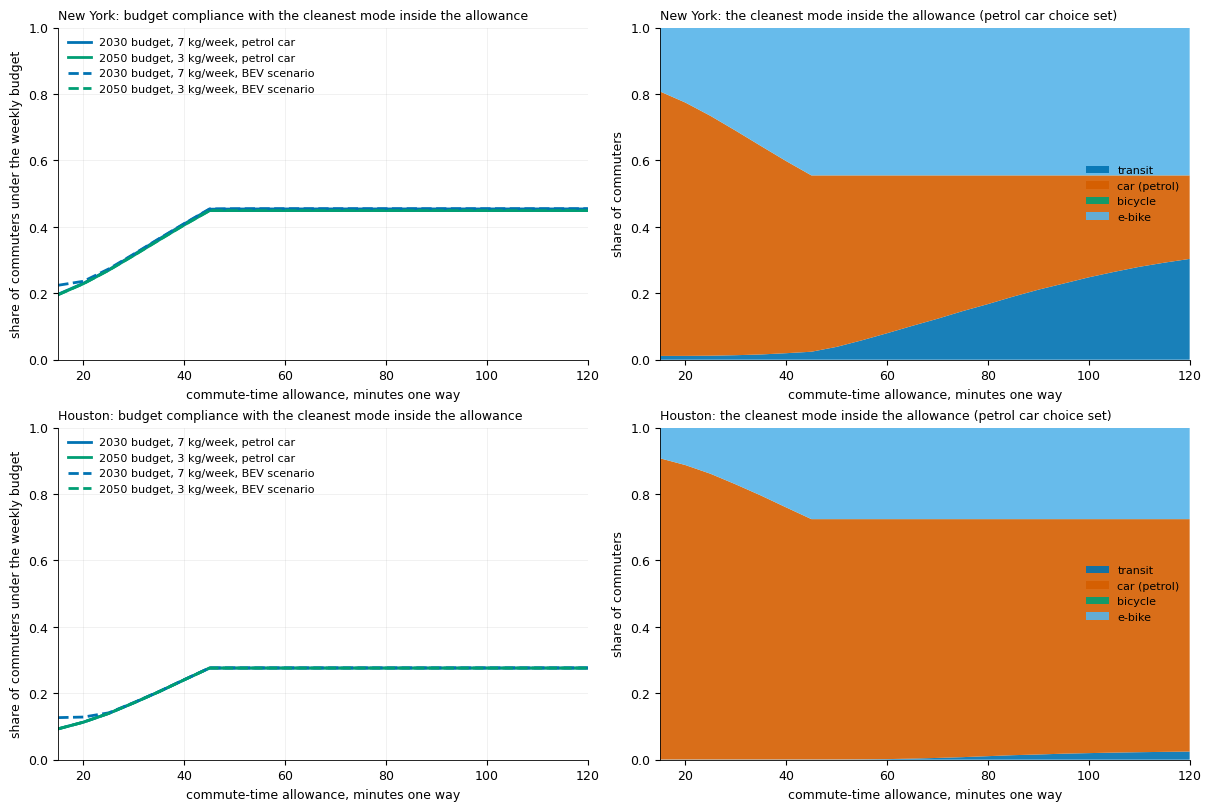

the frontier at selected allowances:


share with no mode inside the allowance  \
area     scenario     allowance_min                                            
New York petrol car   30                                               0.520   
                      45                                               0.270   
                      60                                               0.135   
                      90                                               0.034   
                      120                                              0.006   
         BEV scenario 30                                               0.520   
                      45                                               0.270   
                      60                                               0.135   
                      90                                               0.034   
                      120                                              0.006   
Houston  petrol car   30                                               0.677   
                      45                                               0.355   
                      60                                               0.142   
                      90                                               0.018   
                      120                                              0.000   
         BEV scenario 30                                               0.677   
                      45                                               0.355   
                      60                                               0.142   
                      90                                               0.018   
                      120                                              0.000   

                                     median weekly kg  2030 budget, 7 kg/week  \
area     scenario     allowance_min                                             
New York petrol car   30                       33.382                   0.317   
                      45                       30.959                   0.453   
                      60                       13.637                   0.454   
                      90                       12.344                   0.454   
                      120                      12.339                   0.454   
         BEV scenario 30                       19.890                   0.318   
                      45                       18.487                   0.454   
                      60                       12.749                   0.455   
                      90                       11.995                   0.455   
                      120                      11.993                   0.455   
Houston  petrol car   30                       52.464                   0.171   
                      45                       52.443                   0.276   
                      60                       52.441                   0.276   
                      90                       52.263                   0.276   
                      120                      52.061                   0.276   
         BEV scenario 30                       26.249                   0.172   
                      45                       26.240                   0.277   
                      60                       26.240                   0.277   
                      90                       26.240                   0.277   
                      120                      26.240                   0.277   

                                     2050 budget, 3 kg/week  
area     scenario     allowance_min                          
New York petrol car   30                              0.314  
                      45                              0.449  
                      60                              0.449  
                      90                              0.449  
                      120                             0.449  
         BEV scenario 30                              0.314

In [5]:
ALLOWANCES = np.arange(15, 125, 5)


def cleanest_within(table, modes, allowance):
    # Per flow: the mode with the fewest grams among those within the allowance; the fastest mode where none is.
    minutes = table[[f"minutes_{m}" for m in modes]].to_numpy()
    grams = table[[f"grams_{m}" for m in modes]].to_numpy()
    admissible = minutes <= allowance
    grams_adm = np.where(admissible, grams, np.inf)
    choice = np.argmin(grams_adm, axis=1)
    none = ~admissible.any(axis=1)
    fastest = np.nanargmin(np.where(np.isnan(minutes), np.inf, minutes), axis=1)
    choice = np.where(none, fastest, choice)
    rows = np.arange(len(table))
    return np.array(modes)[choice], grams[rows, choice], minutes[rows, choice], none


frontier_rows, mix_rows = [], []
for area, table in flows.items():
    reachable = table.loc[table[[f"minutes_{m}" for m in CHOICE_MODES]].notna().any(axis=1)]
    weights = reachable["workers"].to_numpy()
    for scenario, modes in [("petrol car", CHOICE_MODES), ("BEV scenario", CHOICE_MODES_BEV)]:
        for allowance in ALLOWANCES:
            mode, grams, minutes, none = cleanest_within(reachable, modes, allowance)
            weekly = grams * WEEKLY_PER_GRAM
            row = {"area": area, "scenario": scenario, "allowance_min": allowance,
                   "share with no mode inside the allowance": weights[none].sum() / weights.sum(),
                   "median weekly kg": weighted_median(weekly, weights)}
            for label, budget in BUDGETS_KG.items():
                row[label] = weights[weekly <= budget].sum() / weights.sum()
            frontier_rows.append(row)
            for m in modes:
                mix_rows.append({"area": area, "scenario": scenario, "allowance_min": allowance, "mode": m, "share": weights[mode == m].sum() / weights.sum()})
    # References: everyone drives; everyone takes the cleanest mode they have whatever the time.
    car_weekly = reachable["grams_car"].to_numpy() * WEEKLY_PER_GRAM
    cleanest = np.nanmin(reachable[[f"grams_{m}" for m in CHOICE_MODES]].to_numpy(), axis=1) * WEEKLY_PER_GRAM
    for label, budget in BUDGETS_KG.items():
        print(f"{area}, {label}: car only {np.nansum(weights[car_weekly <= budget]) / weights.sum():.3f} of commuters under budget; "
              f"cleanest mode regardless of time {weights[cleanest <= budget].sum() / weights.sum():.3f}")

frontier = pd.DataFrame(frontier_rows)
mix = pd.DataFrame(mix_rows)

figure, axes = plt.subplots(ncols=2, nrows=len(AREAS), figsize=(12, 4 * len(AREAS)), layout="constrained")
for row, area in enumerate(AREAS):
    axis = axes[row, 0]
    for scenario, style in [("petrol car", "-"), ("BEV scenario", "--")]:
        sub = frontier.loc[(frontier["area"] == area) & (frontier["scenario"] == scenario)]
        for (label, budget), colour in zip(BUDGETS_KG.items(), ["#0072B2", "#009E73"]):
            axis.plot(sub["allowance_min"], sub[label], style, color=colour, linewidth=2, label=f"{label}, {scenario}")
    axis.set_ylim(0, 1)
    axis.set_xlim(ALLOWANCES[0], ALLOWANCES[-1])
    axis.set_xlabel("commute-time allowance, minutes one way")
    axis.set_ylabel("share of commuters under the weekly budget")
    axis.set_title(f"{area}: budget compliance with the cleanest mode inside the allowance", loc="left", fontsize=9)
    axis.grid(alpha=0.25, linewidth=0.5)
    axis.legend(frameon=False, fontsize=8, loc="upper left")

    axis = axes[row, 1]
    sub = mix.loc[(mix["area"] == area) & (mix["scenario"] == "petrol car")].pivot(index="allowance_min", columns="mode", values="share").reindex(columns=CHOICE_MODES)
    axis.stackplot(sub.index, [sub[m] for m in CHOICE_MODES], colors=[COLOURS[m] for m in CHOICE_MODES], labels=[LABELS[m] for m in CHOICE_MODES], alpha=0.9)
    axis.set_ylim(0, 1)
    axis.set_xlim(ALLOWANCES[0], ALLOWANCES[-1])
    axis.set_xlabel("commute-time allowance, minutes one way")
    axis.set_ylabel("share of commuters")
    axis.set_title(f"{area}: the cleanest mode inside the allowance (petrol car choice set)", loc="left", fontsize=9)
    axis.legend(frameon=False, fontsize=8, loc="center right")
figure.savefig(FIGURES / f"05.11-time-budget-frontier-{RUN_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

print("the frontier at selected allowances:")
frontier.loc[frontier["allowance_min"].isin([30, 45, 60, 90, 120])].set_index(["area", "scenario", "allowance_min"]).round(3)

## 5. Maps by home tract

Three pairs of maps, New York beside Houston, each value the worker-weighted statistic over
the tract's residents. Tracts where fewer than half of the residents enter the statistic are
grey.

1. **The time penalty of transit against the car**: the median extra minutes of the transit
   commute, among residents with both itineraries. Diverging: blue where transit is faster,
   orange where slower.
2. **A cleaner commute within 15 minutes**: the share of residents for whom some mode (transit,
   e-bike, bicycle) emits less than the petrol car and takes at most 15 minutes more.
3. **Compliance at a 60-minute allowance**: the share of residents whose weekly commute fits
   the 2030 budget of 7 kg when they take the cleanest mode within 60 minutes one way. The
   60 is a drawn point on the frontier of step 4, set by `ALLOWANCE_MAP`, not a value from
   the data or the paper; the frontier shows every allowance from 15 to 120.

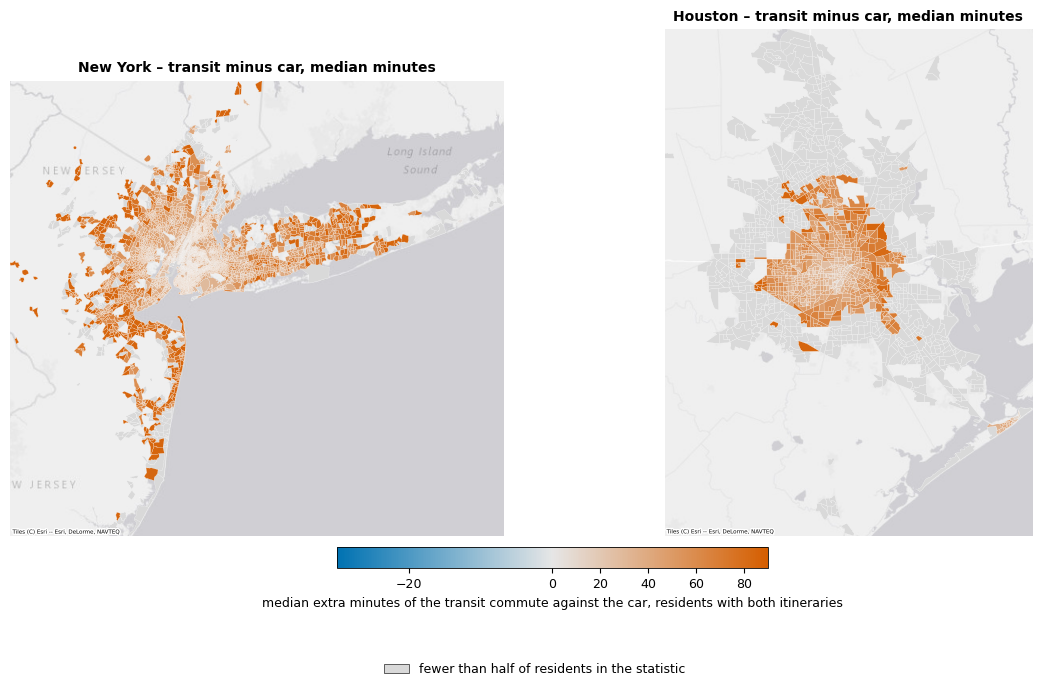

saved figures/05.11-map-transit-time-penalty-us-v4-agency.png


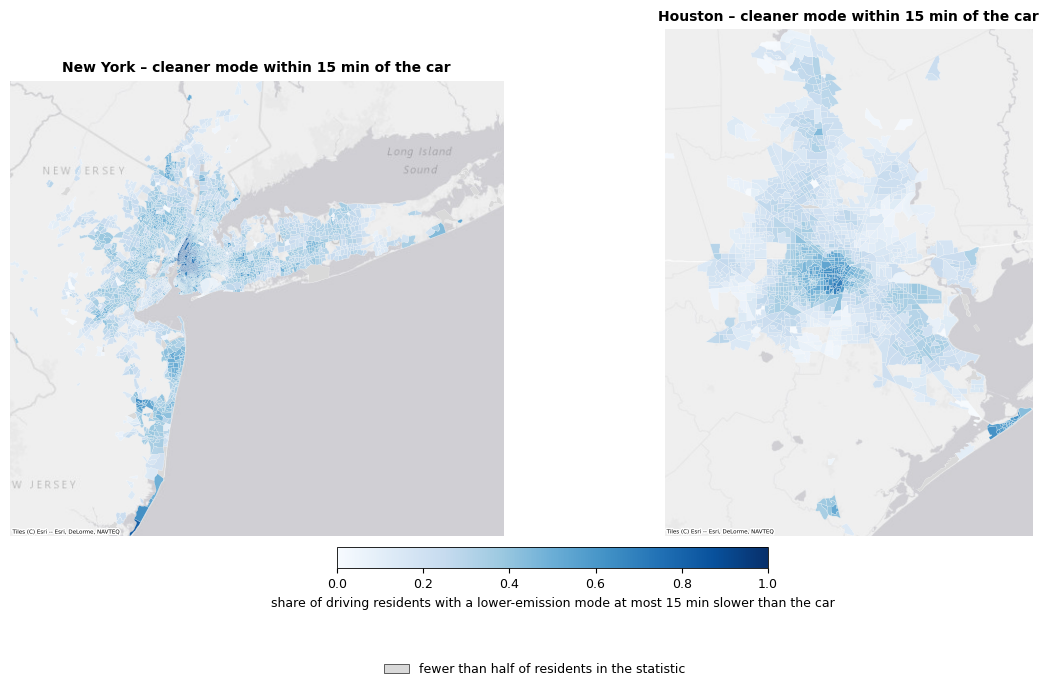

saved figures/05.11-map-cleaner-within-15min-us-v4-agency.png


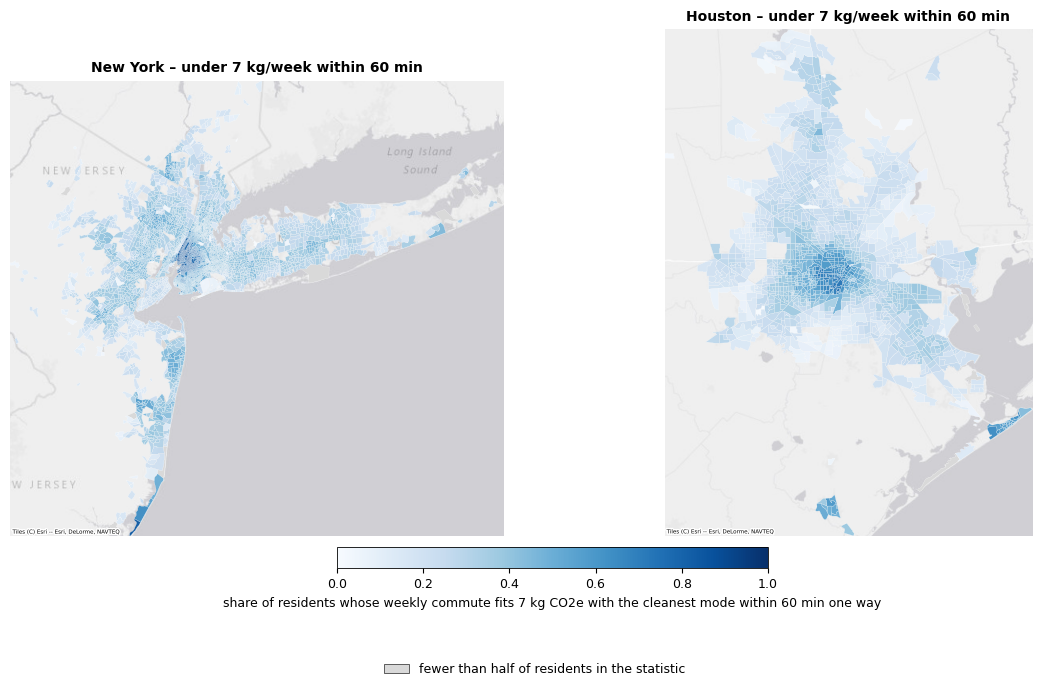

saved figures/05.11-map-compliance-7kg-60min-us-v4-agency.png
New York: tract layer saved, 4,587 tracts
Houston: tract layer saved, 1,445 tracts


In [6]:
def tract_statistic(table, value, weights_mask, fn):
    # Per home tract: fn over the residents selected by weights_mask, and the share of residents selected.
    residents = table.groupby("from_id")["workers"].sum()
    sub = table.loc[weights_mask]
    covered = sub.groupby("from_id")["workers"].sum().reindex(residents.index, fill_value=0) / residents
    stat = sub.groupby("from_id").apply(lambda r: fn(r), include_groups=False).reindex(residents.index)
    return pd.DataFrame({"value": stat, "coverage": covered}).rename_axis("tract").reset_index()


def draw_map(axis, area, layer, column, cmap, norm, title, coverage_floor=0.5):
    data = tracts[area].merge(layer, on="tract", how="left")
    data["value"] = data["value"].where(data["coverage"] >= coverage_floor)
    missing = data.loc[data["value"].isna()]
    if len(missing):
        missing.plot(ax=axis, color=NO_DATA, edgecolor="white", linewidth=0.15)
    present = data.loc[data["value"].notna()]
    if len(present):
        present.plot(ax=axis, column="value", cmap=cmap, norm=norm, edgecolor="white", linewidth=0.15, alpha=0.95)
    west, south, east, north = data.total_bounds
    axis.set_xlim(west, east)
    axis.set_ylim(south, north)
    try:
        ctx.add_basemap(axis, source=BASEMAP, attribution_size=4)
    except Exception as error:
        print(f"{area}: basemap not drawn ({type(error).__name__}: {str(error)[:100]})")
    axis.set_xticks([])
    axis.set_yticks([])
    for spine in axis.spines.values():
        spine.set_visible(False)
    axis.set_aspect("equal")
    axis.set_title(title, fontsize=10, fontweight="bold", pad=6)
    return data


def map_pair(layers, cmap, norm, titles, colorbar_label, filename, extra_handle=None):
    figure, axes = plt.subplots(ncols=len(AREAS), figsize=(7 * len(AREAS), 7))
    for axis, area in zip(axes, AREAS):
        draw_map(axis, area, layers[area], "value", cmap, norm, f"{area} – {titles}")
    mappable = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    bar = figure.colorbar(mappable, ax=axes, orientation="horizontal", fraction=0.04, pad=0.02, shrink=0.5)
    bar.set_label(colorbar_label)
    figure.legend(handles=[mpatches.Patch(facecolor=NO_DATA, edgecolor="#444444", linewidth=0.6, label="fewer than half of residents in the statistic")],
                  loc="lower center", bbox_to_anchor=(0.5, -0.06), frameon=False, fontsize=9)
    png = FIGURES / filename
    figure.savefig(png, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(figure)
    print(f"saved {png}")


# 1. The time penalty of transit against the car.
penalty = {}
for area, table in flows.items():
    both = table["minutes_car"].notna() & table["minutes_transit"].notna()
    extra = table["minutes_transit"] - table["minutes_car"]
    penalty[area] = tract_statistic(table.assign(extra=extra), "extra", both, lambda r: weighted_median(r["extra"], r["workers"]))
map_pair(penalty, DIVERGING, mcolors.TwoSlopeNorm(vmin=-30, vcenter=0, vmax=90), "transit minus car, median minutes",
         "median extra minutes of the transit commute against the car, residents with both itineraries", f"05.11-map-transit-time-penalty-{RUN_TAG}.png")

# 2. A cleaner commute within TOLERANCE_MIN of the car.
cleaner = {}
for area, table in flows.items():
    drivers = table["minutes_car"].notna()
    has_cleaner = np.zeros(len(table), dtype=bool)
    for mode in ALTERNATIVES:
        has_cleaner |= (table[f"minutes_{mode}"] <= table["minutes_car"] + TOLERANCE_MIN) & (table[f"grams_{mode}"] < table["grams_car"])
    layer = tract_statistic(table.assign(cleaner=has_cleaner.astype(float)), "cleaner", drivers, lambda r: np.average(r["cleaner"], weights=r["workers"]))
    cleaner[area] = layer
map_pair(cleaner, SEQUENTIAL, mcolors.Normalize(vmin=0, vmax=1), f"cleaner mode within {TOLERANCE_MIN} min of the car",
         f"share of driving residents with a lower-emission mode at most {TOLERANCE_MIN} min slower than the car", f"05.11-map-cleaner-within-{TOLERANCE_MIN}min-{RUN_TAG}.png")

# 3. Compliance with the 2030 budget at the ALLOWANCE_MAP allowance.
compliance = {}
for area, table in flows.items():
    reachable = table[[f"minutes_{m}" for m in CHOICE_MODES]].notna().any(axis=1)
    sub = table.loc[reachable]
    _, grams, _, _ = cleanest_within(sub, CHOICE_MODES, ALLOWANCE_MAP)
    under = pd.Series(0.0, index=table.index)
    under.loc[sub.index] = (grams * WEEKLY_PER_GRAM <= BUDGETS_KG["2030 budget, 7 kg/week"]).astype(float)
    compliance[area] = tract_statistic(table.assign(under=under), "under", reachable, lambda r: np.average(r["under"], weights=r["workers"]))
map_pair(compliance, SEQUENTIAL, mcolors.Normalize(vmin=0, vmax=1), f"under 7 kg/week within {ALLOWANCE_MAP} min",
         f"share of residents whose weekly commute fits 7 kg CO2e with the cleanest mode within {ALLOWANCE_MAP} min one way", f"05.11-map-compliance-7kg-{ALLOWANCE_MAP}min-{RUN_TAG}.png")

# The tract layers, saved for reuse.
for area, folder in AREAS.items():
    out = pd.concat([penalty[area].rename(columns={"value": "transit_extra_minutes_median", "coverage": "share_with_both_itineraries"}),
                     cleaner[area].drop(columns="tract").rename(columns={"value": f"share_cleaner_within_{TOLERANCE_MIN}min", "coverage": "share_drivers"}),
                     compliance[area].drop(columns="tract").rename(columns={"value": f"share_under_7kg_within_{ALLOWANCE_MAP}min", "coverage": "share_with_any_itinerary"})], axis=1)
    out.to_parquet(folder / f"tract-time-vs-emissions-{RUN_TAG}-{YEAR}.parquet", index=False)
    print(f"{area}: tract layer saved, {len(out):,} tracts")